# Baseline Model Benchmarking

## Introduction
The purpose of this notebook is to establish and compare baseline machine learning models for predicting cervical cancer biopsy outcomes using the Cervical Cancer (Risk Factors) dataset.

**The main objectives are:**

* **To prepare the data for modeling** (train-test split, handling missing values, feature scaling).
* **To build baseline classification models** including Logistic Regression, Random Forest, Support Vector Machine, and XGBoost.
* **To evaluate model performance** using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrix.
* **To compare models objectively** and identify the strongest baseline approach.

This benchmarking step provides a reference point for future model optimization and improvement.

In [1]:
#Import libraries for data manipulation, visualization, preprocessing, model training, and performance evaluation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve

In [2]:
#Load the Cervical Cancer (Risk Factors) dataset into a pandas DataFrame
df = pd.read_csv("risk_factors_cervical_cancer.csv")

In [3]:
#Clean the dataset, split into features and target, perform train-test split, and impute missing values using median strategy
df = df.replace('?', np.nan)
df = df.apply(pd.to_numeric, errors='coerce')

X = df.drop("Biopsy", axis=1)
y = df["Biopsy"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [4]:
# Standardize features by fitting the scaler on training data and applying it to both training and test sets
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
#Define baseline classification models for performance comparison
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(random_state=42, class_weight='balanced'),
    "SVM": SVC(class_weight='balanced', probability=True),
    "XGBoost": XGBClassifier(eval_metric='logloss', scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum())
}

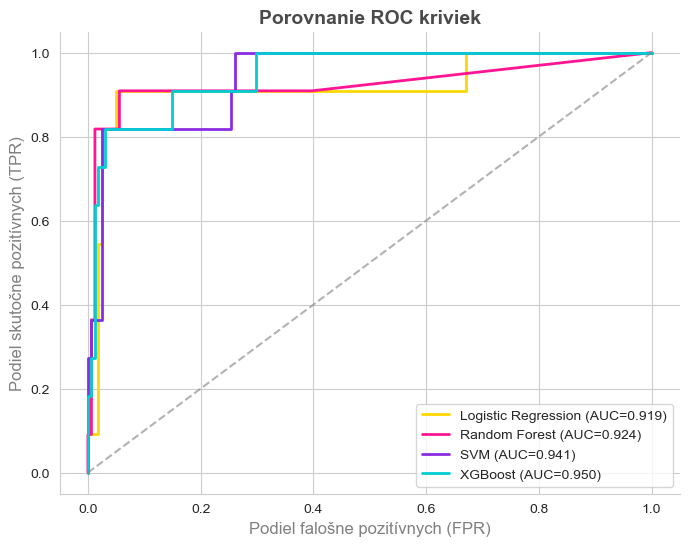

In [6]:
# Train each baseline model, evaluate performance metrics, store results, and plot ROC curves for comparison
results = []

line_colors = ["#FFD700", "#FF1493", "#8A2BE2", "#00CED1"]

plt.figure(figsize=(8, 6))
sns.set_style("whitegrid")

for i, (name, model) in enumerate(models.items()):
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # === Probability for ROC ===
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)
    
    # === Metrics ===
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "ROC-AUC": auc
    })
    
    # === ROC Curve ===
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    
    current_color = line_colors[i % len(line_colors)]
    
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", color=current_color, linewidth=2)

plt.plot([0,1], [0,1], linestyle='--', color='gray', alpha=0.6)
plt.xlabel("Podiel falošne pozitívnych (FPR)", fontsize=12, color='gray')
plt.ylabel("Podiel skutočne pozitívnych (TPR)", fontsize=12, color='gray')
plt.title("Porovnanie ROC kriviek", fontsize=14, fontweight='bold', color='#4A4A4A')

plt.legend(loc="lower right", frameon=True)
sns.despine()
plt.show()

In [7]:
# Create a results DataFrame, sort models by ROC-AUC score, and display the final benchmarking table
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="ROC-AUC", ascending=False)

print("\nFINAL BENCHMARKING TABLE:")
df_results


FINAL BENCHMARKING TABLE:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
3,XGBoost,0.965116,0.727273,0.727273,0.727273,0.949746
2,SVM,0.959302,0.666667,0.727273,0.695652,0.941276
1,Random Forest,0.959302,0.750000,0.545455,0.631579,0.924054
0,Logistic Regression,0.959302,0.642857,0.818182,0.720000,0.919255


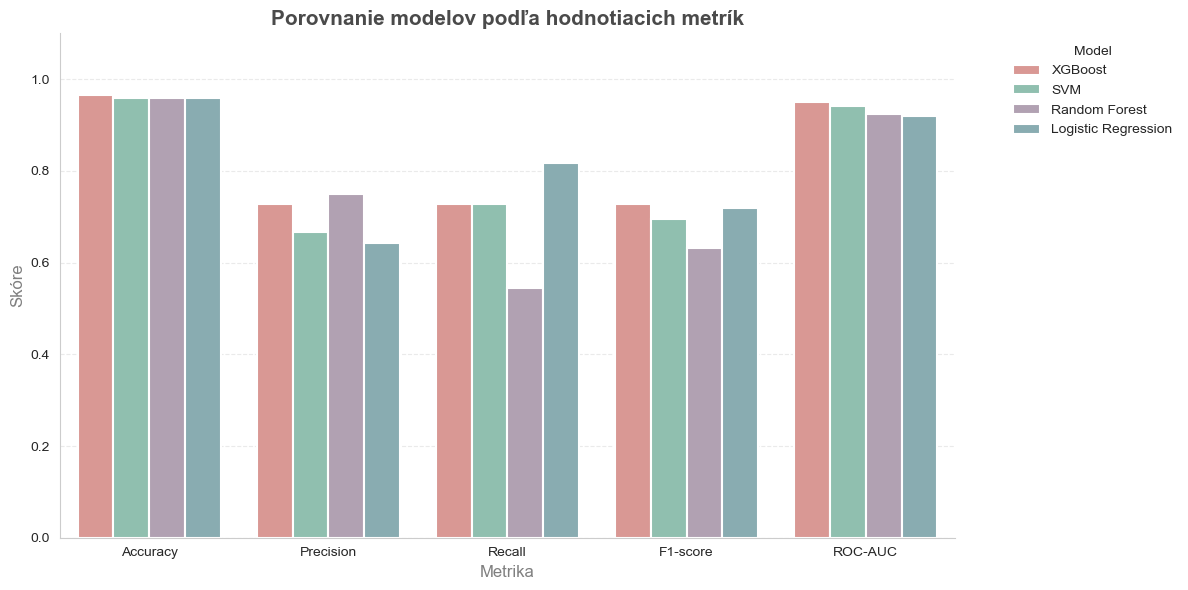

In [8]:
#Melt the results DataFrame to a long format and visualize model performance across multiple metrics using a grouped bar chart
sns.set_style("whitegrid")

df_melted = df_results.melt(id_vars="Model", 
                            value_vars=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
                            var_name="Metric", 
                            value_name="Score")

plt.figure(figsize=(12, 6))

main_colors = ["#E58E88", "#88C7B1", "#B39EB5", "#82B1B8"]

ax = sns.barplot(
    data=df_melted,
    x="Metric",
    y="Score",
    hue="Model",
    palette=main_colors,
    linewidth=1.5
)

plt.title("Porovnanie modelov podľa hodnotiacich metrík", fontsize=15, fontweight="bold", color="#4A4A4A")
plt.xlabel("Metrika", fontsize=12, color='gray')
plt.ylabel("Skóre", fontsize=12, color='gray')

plt.ylim(0, 1.1)
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.4)

sns.despine()
plt.tight_layout()
plt.show()

The baseline models were evaluated on an imbalanced dataset, where the number of positive cases (cervical cancer) is significantly lower than the number of negative cases.

Although some models achieved relatively high accuracy, the recall scores for the positive class remain low. This indicates that the models struggle to correctly identify patients with the disease, which is critical in a medical context.

These results represent a **pessimistic baseline scenario**, where only basic preprocessing (median imputation and scaling) and class balancing techniques were applied.

In the next phase of the project, the performance will be improved by:

* applying more advanced imputation methods
* addressing class imbalance using SMOTE
* performing hyperparameter tuning

The primary goal will be to significantly improve recall, ensuring that as many positive cases as possible are correctly identified.
